# Лабораторная работа №1. Регрессия: Wine Quality

**Цель:** предсказать оценку качества вина `quality` по физико-химическим измерениям и сравнить константный прогноз, линейную регрессию, случайный лес и градиентный бустинг.

Источник: [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality), Cortez et al. (2009), DOI: [10.24432/C56S3T](https://doi.org/10.24432/C56S3T), лицензия CC BY 4.0.
Используем **winequality-red.csv**: красное португальское Vinho Verde. Вид вина в ТЗ не уточнён; здесь выбран один однородный набор. Выводы не следует автоматически переносить на белое вино.

Основная метрика — **RMSE**, дополнительная — **MAE**. Порог задания — RMSE < 0.70 на скрытом тесте преподавателя. Локальная оценка не гарантирует прохождения этого порога на другой выборке.

Порядок работы: загрузка → проверка данных → фиксированное разбиение → исследование train → кросс-валидация и выбор модели → однократная итоговая оценка всех моделей → анализ ошибок заранее выбранной модели.

In [1]:
import sys
import platform
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True})
print('Python:', platform.python_version())
print('numpy:', np.__version__, '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__)

Python: 3.14.4
numpy: 2.5.4 | pandas: 3.1.0 | sklearn: 1.9.1


## 1. Загрузка и проверка данных

CSV использует разделитель `;`. Если файл уже лежит в `regression/data`, интернет не требуется. При первом запуске скачивается официальный архив UCI. `quality` исключается из признаков; идентификаторов среди признаков нет.

In [2]:
# Ячейка работает при запуске из корня репозитория и из папки regression.
BASE_DIR = Path('regression') if Path('regression/lab01.pdf').exists() else Path('.')
DATA_PATH = BASE_DIR / 'data' / 'winequality-red.csv'
DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists():
    url = 'https://archive.ics.uci.edu/static/public/186/wine+quality.zip'
    try:
        with urlopen(url, timeout=60) as response:
            archive = response.read()
        with ZipFile(BytesIO(archive)) as z:
            name = next(n for n in z.namelist() if n.endswith('winequality-red.csv'))
            DATA_PATH.write_bytes(z.read(name))
    except Exception as exc:
        raise RuntimeError(
            f'Не удалось скачать UCI. Скачайте winequality-red.csv вручную '
            f'и сохраните в {DATA_PATH.resolve()}, затем повторите запуск.'
        ) from exc

raw = pd.read_csv(DATA_PATH, sep=';')
expected = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
            'chlorides', 'free sulfur dioxide', 'total sulfur dioxide',
            'density', 'pH', 'sulphates', 'alcohol', 'quality']
assert list(raw.columns) == expected, 'Проверьте формат и вид датасета'
assert all(pd.api.types.is_numeric_dtype(raw[c]) for c in raw.columns)
assert raw['quality'].notna().all() and raw['quality'].between(0, 10).all()
print('Исходная размерность:', raw.shape)
print('Полных дубликатов:', raw.duplicated().sum())
display(raw.isna().sum().rename('Число пропусков').to_frame())

# Не увеличиваем вес одинаковых наблюдений за счёт полных повторов строк.
data = raw.drop_duplicates().copy()
X = data.drop(columns='quality')
y = data['quality']
# Даже совпадающие признаки с разными оценками не должны попадать в разные части.
groups = X.groupby(list(X.columns), dropna=False, sort=False).ngroup()
print('После удаления полных дубликатов:', data.shape)
print('Групп одинаковых наборов признаков:', groups.nunique())

Исходная размерность: (1599, 12)
Полных дубликатов: 240


,Число пропусков
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


После удаления полных дубликатов: (1359, 12)
Групп одинаковых наборов признаков: 1359


**Почему учитываем повторы.** В наборе могут встречаться одинаковые записи. Их попадание одновременно в train и test позволяет модели фактически узнать тестовый объект заранее. Полные повторы удаляем; наблюдения с одинаковыми признаками и разными оценками сохраняем, но объединяем в группу при всех разбиениях. Это правило задано до оценки моделей.

Проверка структуры и дубликатов использует весь файл только для контроля целостности и формирования независимых групп. Распределения, корреляции и все обучаемые преобразования далее оцениваются по train.

## 2. Подготовка выборок

Отводим примерно **80%** данных на обучение и **20%** на финальный тест. При таком размере остаётся достаточно объектов для обучения, а тест содержит несколько сотен наблюдений. `GroupShuffleSplit` случайно делит группы одинаковых признаков, поэтому доля строк может немного отличаться от 20%. Фиксируем `random_state=42`. Временной информации нет, поэтому временное разбиение не обосновано.

Внутри train используем одинаковые пять групповых фолдов для всех моделей. Тест не участвует в подборе параметров, выборе модели, масштабировании и заполнении пропусков. Повторный подбор по тестовым оценкам привёл бы к переобучению на тест и оптимистичной оценке качества.

In [3]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, groups=groups))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]
assert set(groups_train).isdisjoint(set(groups_test))
assert 'quality' not in X_train.columns
cv_splits = list(GroupKFold(n_splits=5).split(X_train, y_train, groups_train))
for a, b in cv_splits:
    assert set(groups_train.iloc[a]).isdisjoint(set(groups_train.iloc[b]))
print(f'Train: {len(X_train)} ({len(X_train)/len(X):.1%}); '
      f'test: {len(X_test)} ({len(X_test)/len(X):.1%})')

Train: 1087 (80.0%); test: 272 (20.0%)


## 3. Исследование обучающей выборки

`quality` — порядковая оценка дегустаторов, которую в этой задаче рассматриваем как числовую цель регрессии. Дробные прогнозы допустимы: округление изменило бы оцениваемую модель. Проверим баланс оценок, масштабы признаков, выбросы и связи с целью. Редкие крайние оценки ожидаемо сложнее предсказывать: примеров для них меньше.

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1087.0,8.293376,1.726004,4.60000,7.1000,7.9000,9.1000,15.90000
volatile acidity,1087.0,0.527732,0.178433,0.16000,0.3900,0.5200,0.6400,1.58000
citric acid,1087.0,0.273303,0.195378,0.00000,0.1000,0.2600,0.4200,1.00000
residual sugar,1087.0,2.525483,1.365678,0.90000,1.9000,2.2000,2.6000,15.50000
chlorides,1087.0,0.089592,0.052481,0.01200,0.0700,0.0800,0.0910,0.61100
free sulfur dioxide,1087.0,15.740570,10.335814,1.00000,7.0000,14.0000,21.0000,72.00000
total sulfur dioxide,1087.0,46.849126,33.300148,6.00000,22.0000,38.0000,63.0000,289.00000
density,1087.0,0.996698,0.001863,0.99007,0.9956,0.9967,0.9978,1.00369
pH,1087.0,3.309540,0.152251,2.74000,3.2100,3.3100,3.4000,3.90000
sulphates,1087.0,0.659669,0.173844,0.33000,0.5500,0.6200,0.7300,2.00000


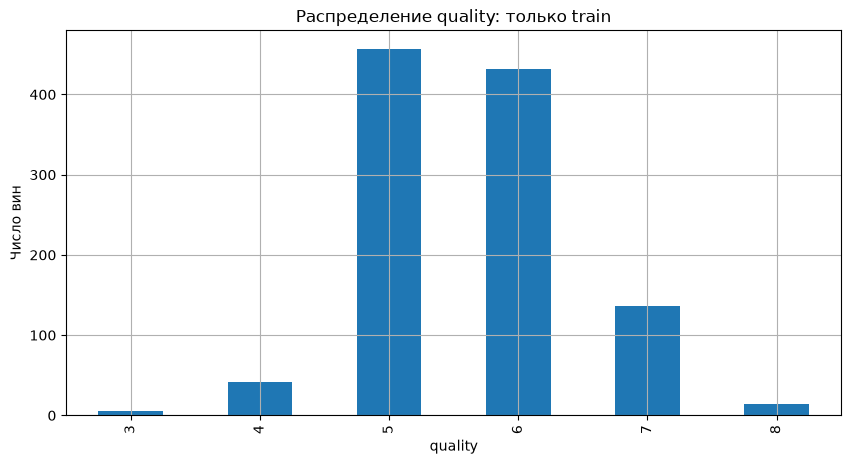

**Вывод.** Две наиболее частые оценки: [5, 6]; на них приходится 81.8% train. Крайние оценки представлены меньшим числом примеров. Поэтому общей метрики недостаточно: ниже отдельно проверяем ошибки по значениям quality.

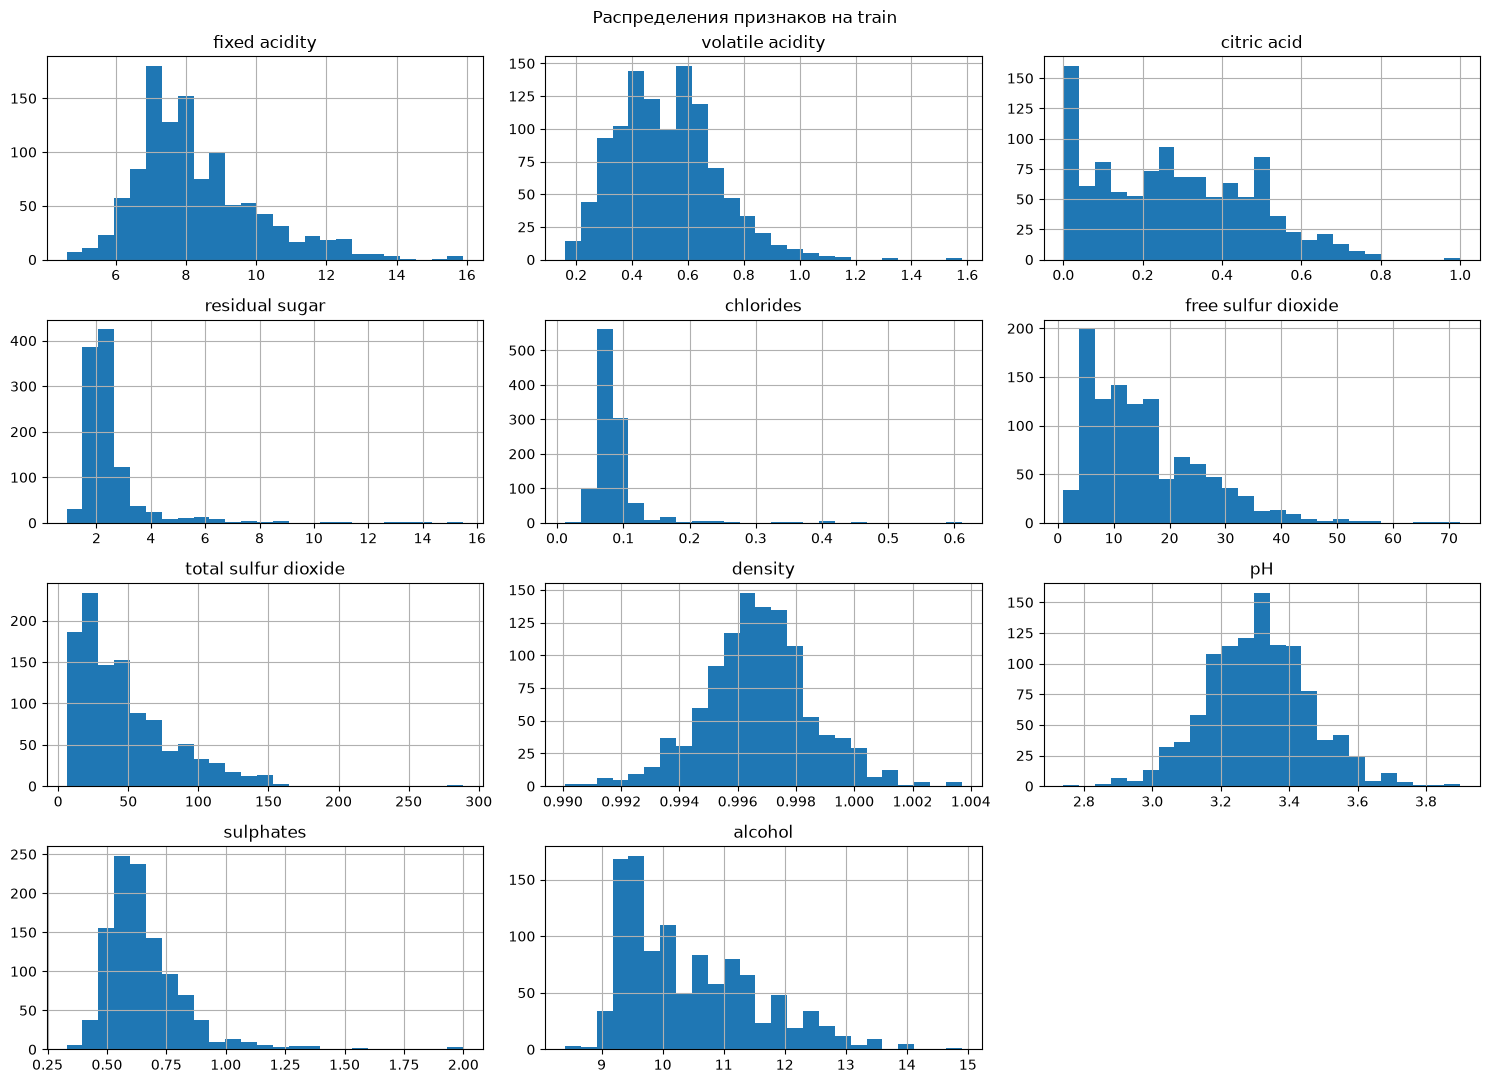

In [4]:
train = X_train.assign(quality=y_train)
display(train.describe().T)
counts = y_train.value_counts().sort_index()
counts.plot.bar(title='Распределение quality: только train', xlabel='quality', ylabel='Число вин')
plt.show()
majority = counts.nlargest(2)
display(Markdown(
    f'**Вывод.** Две наиболее частые оценки: {list(majority.index)}; '
    f'на них приходится {majority.sum()/len(y_train):.1%} train. '
    f'Крайние оценки представлены меньшим числом примеров. '
    'Поэтому общей метрики недостаточно: ниже отдельно проверяем ошибки по значениям quality.'
))

X_train.hist(bins=25, figsize=(15, 11))
plt.suptitle('Распределения признаков на train')
plt.tight_layout()
plt.show()

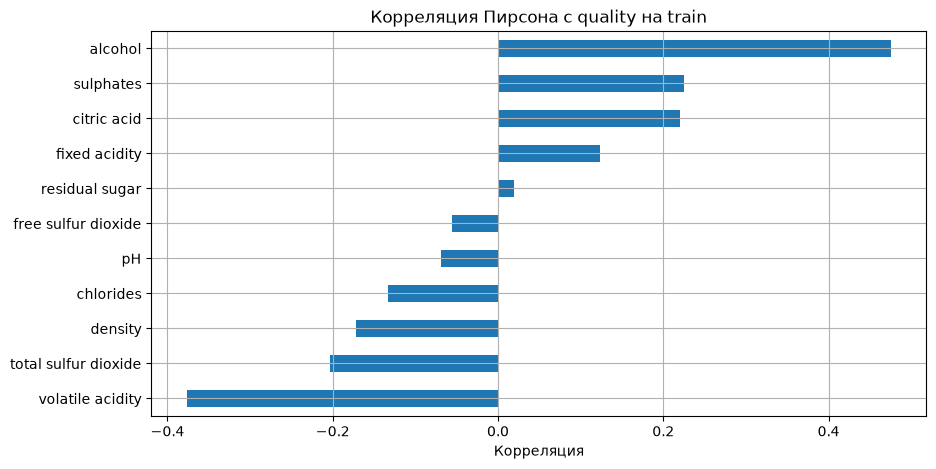

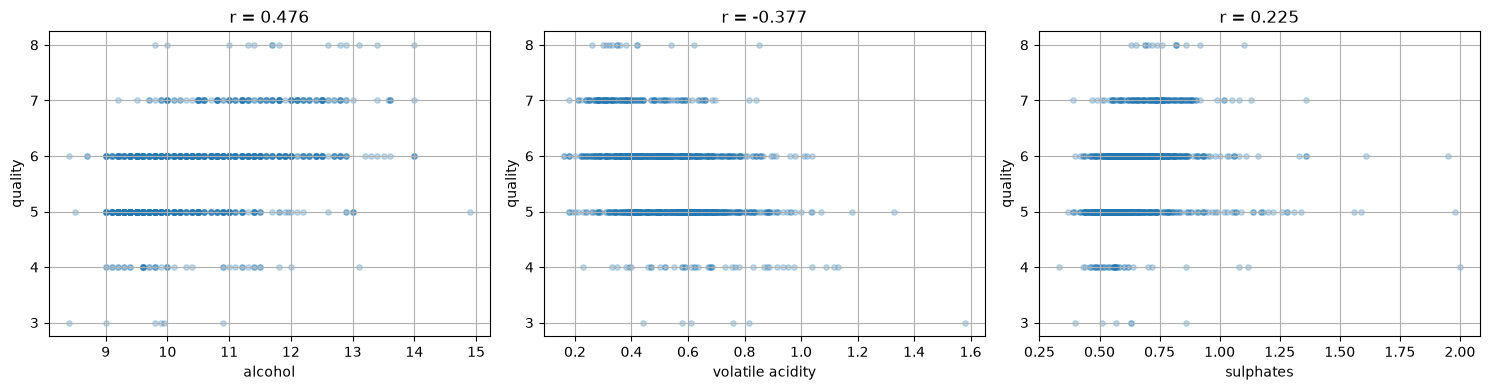

**Выводы о связях с целью.**

- `alcohol`: r=0.476. Более высокие значения связаны в среднем с более высокой оценкой. Это полезный кандидат для прогноза, но корреляция не доказывает причинность и не описывает все нелинейные зависимости.

- `volatile acidity`: r=-0.377. Более высокие значения связаны в среднем с более низкой оценкой. Это полезный кандидат для прогноза, но корреляция не доказывает причинность и не описывает все нелинейные зависимости.

- `sulphates`: r=0.225. Более высокие значения связаны в среднем с более высокой оценкой. Это полезный кандидат для прогноза, но корреляция не доказывает причинность и не описывает все нелинейные зависимости.

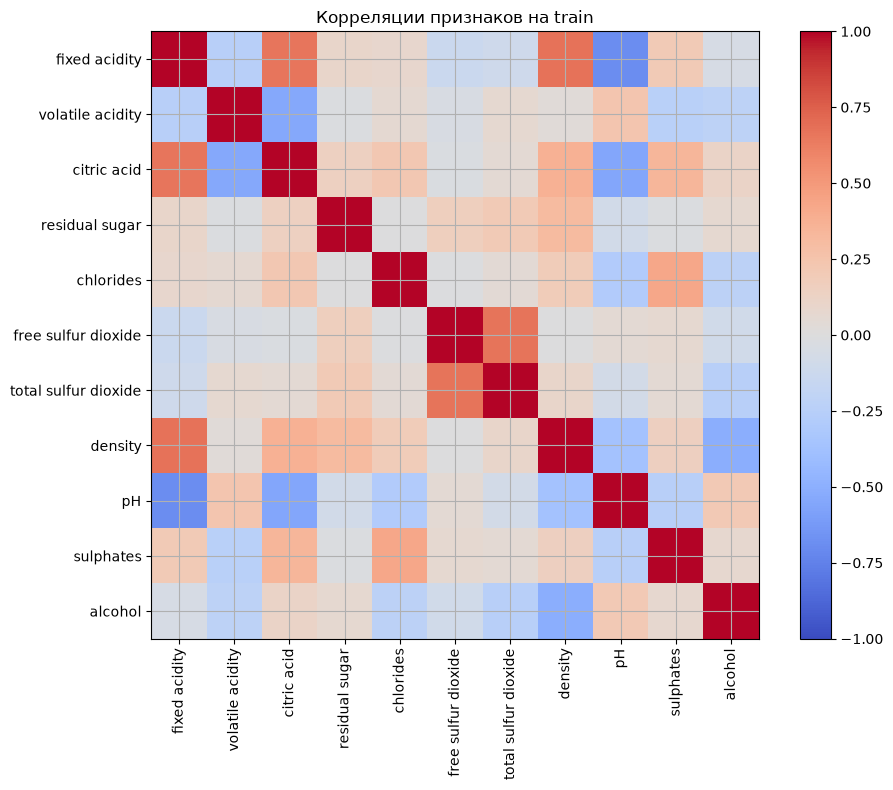

In [5]:
corr = train.corr()['quality'].drop('quality').sort_values()
corr.plot.barh(title='Корреляция Пирсона с quality на train', xlabel='Корреляция')
plt.show()
strongest = corr.abs().nlargest(3).index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, strongest):
    ax.scatter(X_train[feature], y_train, alpha=0.25, s=15)
    ax.set(xlabel=feature, ylabel='quality', title=f'r = {corr[feature]:.3f}')
plt.tight_layout()
plt.show()

display(Markdown('**Выводы о связях с целью.**\n\n' + '\n\n'.join(
    f'- `{f}`: r={corr[f]:.3f}. Более высокие значения связаны в среднем с '
    f'{"более высокой" if corr[f] > 0 else "более низкой"} оценкой. '
    'Это полезный кандидат для прогноза, но корреляция не доказывает причинность '
    'и не описывает все нелинейные зависимости.' for f in strongest
)))
feature_corr = X_train.corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(feature_corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(X.columns)), X.columns, rotation=90)
ax.set_yticks(range(len(X.columns)), X.columns)
fig.colorbar(im, ax=ax)
ax.set_title('Корреляции признаков на train')
plt.tight_layout()
plt.show()

**Вывод для моделирования.** Признаки имеют разные единицы измерения: например, pH, содержание алкоголя и концентрации соединений. Перед линейной регрессией применяем `StandardScaler`, чтобы коэффициенты соответствовали изменению признака на одно стандартное отклонение. Деревьям масштабирование не требуется: они выбирают пороги по отдельным признакам. Связанные признаки могут разделять важность между собой; коэффициенты линейной модели при этом могут быть нестабильны. Не удаляем наблюдения только из-за больших значений: необычный химический состав может быть реальным.

## 4. Метрики и baseline

Для ошибок $e_i=y_i-\hat y_i$:

$$MAE=\frac{1}{n}\sum_i |e_i|, \qquad RMSE=\sqrt{\frac{1}{n}\sum_i e_i^2}.$$

Обе метрики измеряются в баллах качества. MAE показывает среднюю абсолютную величину промаха. RMSE сильнее реагирует на крупные ошибки, поскольку до усреднения ошибка возводится в квадрат: промах на 2 балла даёт вклад 4, а промах на 1 — вклад 1. RMSE не меньше MAE; заметный разрыв обычно указывает на неоднородные ошибки и наличие крупных промахов.

Оптимальная константа для MSE и RMSE — **среднее значение цели на обучении**: минимум суммы квадратов достигается при $c=\overline y_{train}$. Медиана оптимальна для MAE, но основной метрикой здесь является RMSE. `DummyRegressor(strategy='mean')` пересчитывает константу внутри каждого обучающего фолда. Итоговую тестовую оценку baseline вычислим вместе с другими моделями в конце.

## 5. Обучение и выбор модели по train

Для всех моделей используются одни и те же фолды. Заполнение возможных пропусков медианой и масштабирование находятся внутри `Pipeline`, поэтому обучаются заново на каждом фолде. Сетки параметров фиксируем заранее. Выбираем по среднему CV RMSE. Вторая метрика — CV MAE. Стандартное отклонение между фолдами показывает изменчивость оценки, а не доверительный интервал.

Линейная регрессия описывает аддитивную линейную зависимость. Случайный лес усредняет деревья, обученные на случайных подвыборках и подмножествах признаков. Градиентный бустинг последовательно добавляет деревья, исправляющие ошибки текущего ансамбля. Обе модели деревьев способны учитывать взаимодействия и нелинейные зависимости.

In [6]:
models = {
    'Baseline': (make_pipeline(SimpleImputer(strategy='median'), DummyRegressor(strategy='mean')), {}),
    'Linear Regression': (make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), LinearRegression()), {}),
    'Random Forest': (
        make_pipeline(SimpleImputer(strategy='median'), RandomForestRegressor(
            n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)),
        {'randomforestregressor__max_features': [0.7, 1.0],
         'randomforestregressor__min_samples_leaf': [1, 2, 4]}),
    'Gradient Boosting': (
        make_pipeline(SimpleImputer(strategy='median'), GradientBoostingRegressor(random_state=RANDOM_STATE)),
        {'gradientboostingregressor__n_estimators': [150, 300],
         'gradientboostingregressor__learning_rate': [0.03, 0.07],
         'gradientboostingregressor__max_depth': [2, 3]})
}
searches = {}
cv_rows = []
for name, (model, params) in models.items():
    search = GridSearchCV(model, params, cv=cv_splits,
                          scoring={'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error'},
                          refit='RMSE', n_jobs=1, error_score='raise')
    search.fit(X_train, y_train)
    searches[name] = search
    idx = search.best_index_
    cv_rows.append({'Модель': name,
                    'CV RMSE': -search.cv_results_['mean_test_RMSE'][idx],
                    'CV RMSE std': search.cv_results_['std_test_RMSE'][idx],
                    'CV MAE': -search.cv_results_['mean_test_MAE'][idx]})
    print(name, search.best_params_)
cv_results = pd.DataFrame(cv_rows).set_index('Модель').sort_values('CV RMSE')
display(cv_results.round(4))
best_name = cv_results.index[0]
best_model = searches[best_name].best_estimator_
print('Модель для анализа ошибок выбрана до обращения к тесту:', best_name)

Baseline {}
Linear Regression {}
Random Forest {'randomforestregressor__max_features': 0.7, 'randomforestregressor__min_samples_leaf': 4}
Gradient Boosting {'gradientboostingregressor__learning_rate': 0.03, 'gradientboostingregressor__max_depth': 3, 'gradientboostingregressor__n_estimators': 150}


,CV RMSE,CV RMSE std,CV MAE
Модель,,,
Random Forest,0.6521,0.0406,0.5026
Gradient Boosting,0.6617,0.0439,0.5148
Linear Regression,0.6654,0.0445,0.5164
Baseline,0.8183,0.0327,0.6916


Модель для анализа ошибок выбрана до обращения к тесту: Random Forest


## 6. Коэффициенты и важность признаков

У линейной модели коэффициент показывает изменение прогноза при увеличении одного признака на его обучающее стандартное отклонение при фиксированных остальных признаках. Знак задаёт направление связи. Это условная связь, поэтому знак может отличаться от парной корреляции.

У ансамблей используем `feature_importances_`: суммарное нормированное уменьшение ошибки в разбиениях деревьев. Это не коэффициенты регрессии, и их нельзя напрямую сравнивать с величиной линейных коэффициентов. Важности могут быть смещены в пользу признаков с большим числом возможных порогов и распределяться между коррелирующими признаками. Все значения ниже получены из моделей, обученных только на train.

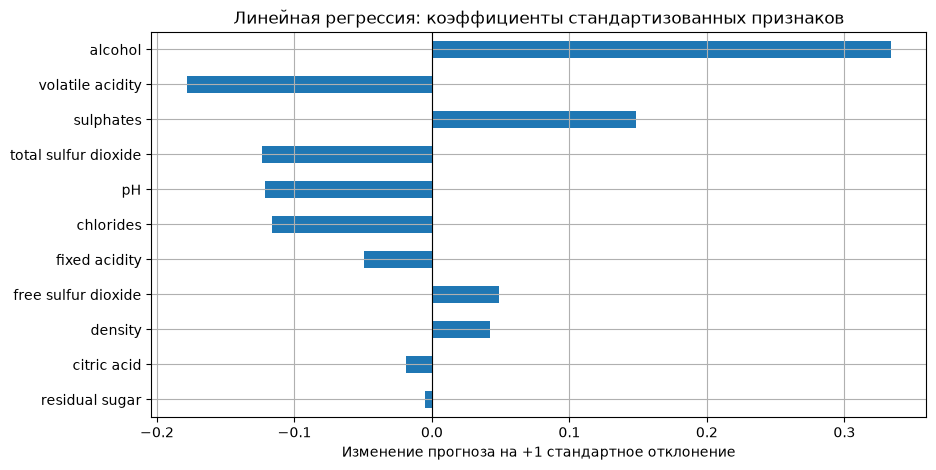

,Коэффициент,Модуль
alcohol,0.333970,0.333970
volatile acidity,-0.178494,0.178494
sulphates,0.148499,0.148499
total sulfur dioxide,-0.123600,0.123600
pH,-0.121548,0.121548
chlorides,-0.115971,0.115971
fixed acidity,-0.049675,0.049675
free sulfur dioxide,0.048723,0.048723
density,0.042064,0.042064
citric acid,-0.019148,0.019148


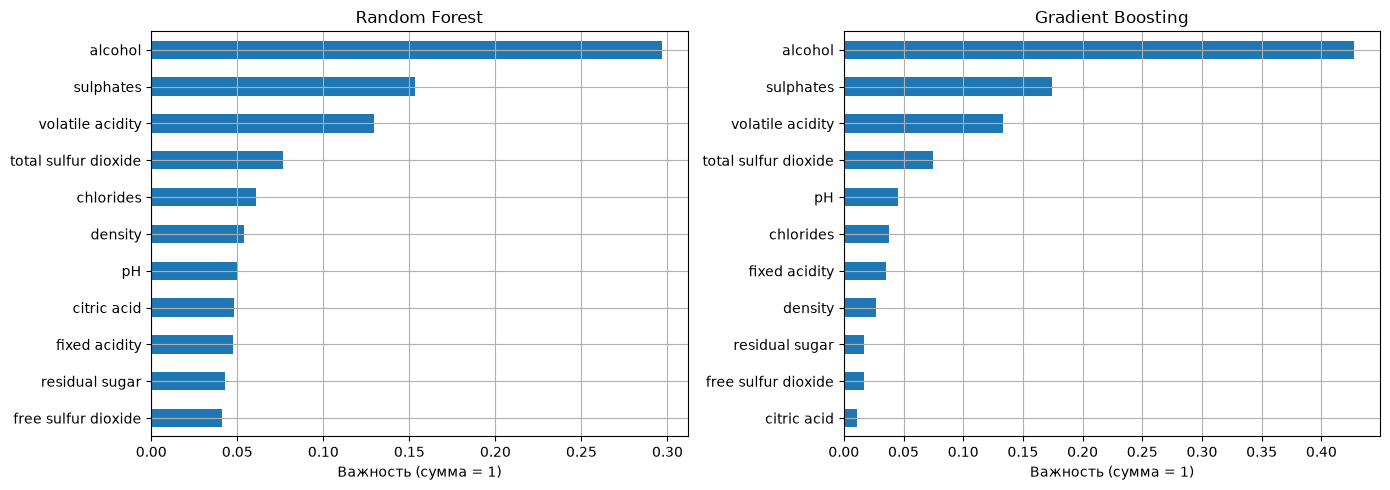

,Random Forest,Gradient Boosting
alcohol,0.296790,0.427689
sulphates,0.153313,0.174111
volatile acidity,0.129483,0.133049
total sulfur dioxide,0.076450,0.074909
chlorides,0.060635,0.037652
density,0.053698,0.026606
pH,0.050561,0.045022
citric acid,0.047966,0.011166
fixed acidity,0.047558,0.035470
residual sugar,0.042610,0.017198


,1 место,2 место,3 место
EDA (модуль корреляции),alcohol,volatile acidity,sulphates
Линейная регрессия (модуль коэффициента),alcohol,volatile acidity,sulphates
Random Forest,alcohol,sulphates,volatile acidity
Gradient Boosting,alcohol,sulphates,volatile acidity


**Сопоставление.** Общие признаки в тройке двух ансамблей: `alcohol`, `sulphates`, `volatile acidity`. Совпадение с EDA означает, что сильная парная связь полезна и в многомерном прогнозе. Расхождения объяснимы: линейная модель оценивает условный линейный вклад, а деревья используют пороги и взаимодействия. Коррелирующие признаки могут заменять друг друга.

In [7]:
linear = searches['Linear Regression'].best_estimator_.named_steps['linearregression']
coefs = pd.Series(linear.coef_, index=X.columns, name='Коэффициент')
coefs.reindex(coefs.abs().sort_values().index).plot.barh(
    title='Линейная регрессия: коэффициенты стандартизованных признаков',
    xlabel='Изменение прогноза на +1 стандартное отклонение')
plt.axvline(0, color='black', linewidth=0.8)
plt.show()
display(coefs.to_frame().assign(Модуль=coefs.abs()).sort_values('Модуль', ascending=False))

importance = pd.DataFrame(index=X.columns)
for name, step in [('Random Forest', 'randomforestregressor'), ('Gradient Boosting', 'gradientboostingregressor')]:
    importance[name] = searches[name].best_estimator_.named_steps[step].feature_importances_
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, importance.columns):
    importance[name].sort_values().plot.barh(ax=ax, title=name, xlabel='Важность (сумма = 1)')
plt.tight_layout()
plt.show()
display(importance.sort_values('Random Forest', ascending=False))

leaders = {
    'EDA (модуль корреляции)': corr.abs().nlargest(3).index.tolist(),
    'Линейная регрессия (модуль коэффициента)': coefs.abs().nlargest(3).index.tolist(),
    'Random Forest': importance['Random Forest'].nlargest(3).index.tolist(),
    'Gradient Boosting': importance['Gradient Boosting'].nlargest(3).index.tolist()
}
display(pd.DataFrame(leaders, index=['1 место', '2 место', '3 место']).T)
common = set(leaders['Random Forest']) & set(leaders['Gradient Boosting'])
display(Markdown(
    '**Сопоставление.** Общие признаки в тройке двух ансамблей: ' +
    (', '.join(f'`{f}`' for f in sorted(common)) or 'отсутствуют') +
    '. Совпадение с EDA означает, что сильная парная связь полезна и в многомерном прогнозе. '
    'Расхождения объяснимы: линейная модель оценивает условный линейный вклад, '
    'а деревья используют пороги и взаимодействия. Коррелирующие признаки могут заменять друг друга.'
))

**Можно ли считать важность доказательством причинности?** Нет. Наблюдательные данные показывают связь, а не результат управляемого изменения состава вина. Например, признак может быть связан с другим химическим свойством, технологией или сортом винограда. Чтобы утверждать причинный эффект, нужны дополнительные предпосылки и специально спланированный эксперимент. Высокая важность не означает, что простое увеличение концентрации улучшит вино.

## 7. Финальная оценка на одном тесте

После выбора параметров и модели по CV оцениваем все четыре заранее подготовленные модели на одной тестовой выборке. Полученные числа — итоговый отчёт, они не используются для нового подбора. Для анализа ошибок сохраняем модель, выбранную по CV, даже если тестовый порядок моделей окажется другим. Прогнозы не округляем и не обрезаем.

In [8]:
def metrics(y_true, pred):
    return {'RMSE': float(np.sqrt(mean_squared_error(y_true, pred))),
            'MAE': float(mean_absolute_error(y_true, pred))}

predictions = {}
rows = []
for name, search in searches.items():
    model = search.best_estimator_
    pred = model.predict(X_test)
    assert np.isfinite(pred).all()
    predictions[name] = pred
    rows.append({'Модель': name, **metrics(y_test, pred)})
results = pd.DataFrame(rows).set_index('Модель')
results['Лучше baseline по RMSE'] = results['RMSE'] < results.loc['Baseline', 'RMSE']
results['RMSE < 0.70'] = results['RMSE'] < 0.70
display(results.round(4))

train_rmse = {name: metrics(y_train, s.best_estimator_.predict(X_train))['RMSE']
              for name, s in searches.items()}
display(pd.DataFrame({'Train RMSE': train_rmse,
                      'CV RMSE': cv_results['CV RMSE'],
                      'Test RMSE': results['RMSE']}).round(4))
passed = results.index[(results.index != 'Baseline') & results['Лучше baseline по RMSE']].tolist()
display(Markdown(
    f'**Итог сравнения.** Baseline: RMSE={results.loc["Baseline", "RMSE"]:.4f}. '
    f'Модели, превзошедшие его: {", ".join(passed) or "нет"}. '
    f'Выбранная по CV модель — **{best_name}**: '
    f'test RMSE={results.loc[best_name, "RMSE"]:.4f}, '
    f'MAE={results.loc[best_name, "MAE"]:.4f}. '
    f'Локальный порог 0.70 {"пройден" if results.loc[best_name, "RMSE"] < 0.70 else "не пройден"}. '
    'Результат скрытого теста пока неизвестен.'
))

,RMSE,MAE,Лучше baseline по RMSE,RMSE < 0.70
Модель,,,,
Baseline,0.8443,0.7049,False,False
Linear Regression,0.6565,0.5041,True,True
Random Forest,0.6107,0.4640,True,True
Gradient Boosting,0.6201,0.4801,True,True


,Train RMSE,CV RMSE,Test RMSE
Baseline,0.8181,0.8183,0.8443
Gradient Boosting,0.5504,0.6617,0.6201
Linear Regression,0.6585,0.6654,0.6565
Random Forest,0.4119,0.6521,0.6107


**Итог сравнения.** Baseline: RMSE=0.8443. Модели, превзошедшие его: Linear Regression, Random Forest, Gradient Boosting. Выбранная по CV модель — **Random Forest**: test RMSE=0.6107, MAE=0.4640. Локальный порог 0.70 пройден. Результат скрытого теста пока неизвестен.

**Интерпретация различий.** Улучшение относительно константы означает, что физико-химические измерения содержат полезную информацию об оценке. Сопоставляем линейную модель с ансамблями: преимущество деревьев согласуется с нелинейными эффектами и взаимодействиями, а близкие результаты означают, что добавленная сложность дала мало пользы. Лес уменьшает разброс отдельных деревьев усреднением; бустинг последовательно уменьшает остаточную ошибку, но чувствителен к глубине и числу деревьев. Их превосходство друг над другом не гарантировано.

Большой разрыв между train и CV/test указывает на переобучение. Порядок по test может отличаться от CV из-за конечного размера выборок, особенно для редких оценок. После этой оценки не меняем сетку и не выбираем другой `random_state`, чтобы «добить» порог: для дальнейших экспериментов понадобилась бы новая независимая проверка.

## 8. Анализ ошибок выбранной модели

Анализ тестовых ошибок ниже служит описанию ограничений финальной модели. По его результатам не переобучаем модель и не выбираем новые признаки в рамках этого эксперимента. Остаток определяем как **истинное значение минус прогноз**: положительный остаток означает недооценку качества.

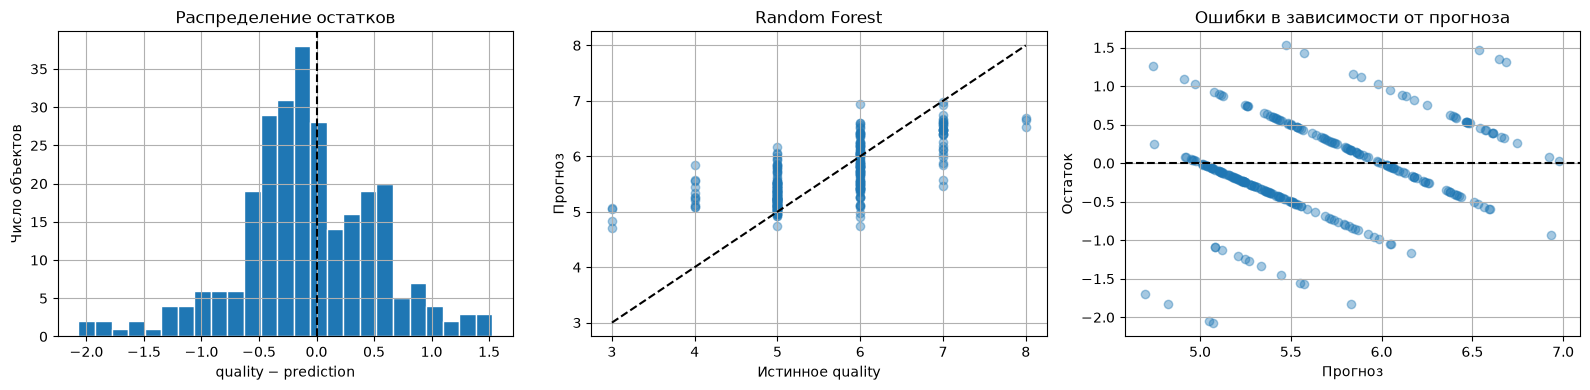

Средний остаток: -0.0786; максимальный абсолютный промах: 2.0695


,Число,RMSE,MAE,Средний прогноз,Средний остаток
quality,,,,,
3,4,1.9163,1.9100,4.9100,-1.9100
4,11,1.3604,1.3414,5.3414,-1.3414
5,120,0.4376,0.3479,5.3378,-0.3378
6,103,0.4578,0.3719,5.8272,0.1728
7,31,0.7215,0.6328,6.3672,0.6328
8,3,1.3787,1.3773,6.6227,1.3773


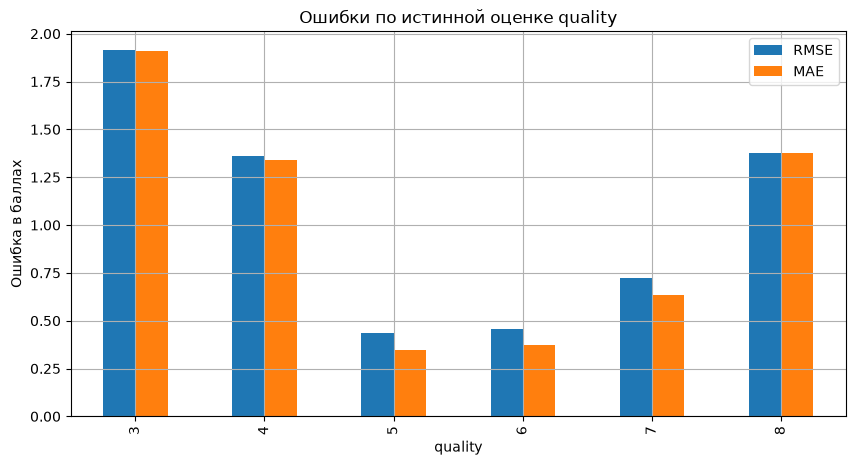

In [9]:
pred = predictions[best_name]
errors = X_test.copy()
errors['quality'] = y_test
errors['prediction'] = pred
errors['residual'] = y_test - pred
errors['abs_error'] = errors['residual'].abs()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(errors['residual'], bins=25, edgecolor='white')
axes[0].axvline(0, color='black', linestyle='--')
axes[0].set(xlabel='quality − prediction', ylabel='Число объектов', title='Распределение остатков')
axes[1].scatter(y_test, pred, alpha=0.4)
limits = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[1].plot(limits, limits, 'k--')
axes[1].set(xlabel='Истинное quality', ylabel='Прогноз', title=best_name)
axes[2].scatter(pred, errors['residual'], alpha=0.4)
axes[2].axhline(0, color='black', linestyle='--')
axes[2].set(xlabel='Прогноз', ylabel='Остаток', title='Ошибки в зависимости от прогноза')
plt.tight_layout()
plt.show()
print(f'Средний остаток: {errors.residual.mean():.4f}; '
      f'максимальный абсолютный промах: {errors.abs_error.max():.4f}')

quality_rows = []
for quality, part in errors.groupby('quality'):
    quality_rows.append({'quality': quality, 'Число': len(part),
                         **metrics(part['quality'], part['prediction']),
                         'Средний прогноз': part['prediction'].mean(),
                         'Средний остаток': part['residual'].mean()})
by_quality = pd.DataFrame(quality_rows).set_index('quality')
display(by_quality.round(4))
by_quality[['RMSE', 'MAE']].plot.bar(title='Ошибки по истинной оценке quality', ylabel='Ошибка в баллах')
plt.show()

In [10]:
worst = errors.nlargest(5, 'abs_error')
display(worst.round(4))

# Сравнение с типичным train показывает необычность состава, но не доказывает причину ошибки.
train_mean = X_train.mean()
train_std = X_train.std().replace(0, np.nan)
observations = []
for idx, row in worst.head(3).iterrows():
    z = ((row[X.columns] - train_mean) / train_std).abs().sort_values(ascending=False)
    feature = z.index[0]
    train_count = int((y_train == row['quality']).sum())
    direction = 'недооценка' if row['residual'] > 0 else 'переоценка'
    observations.append(
        f'- Строка CSV с индексом `{idx}`: истинная оценка {row["quality"]:.0f}, '
        f'прогноз {row["prediction"]:.2f}; {direction} на {row["abs_error"]:.2f} балла. '
        f'На train оценка {row["quality"]:.0f} встречалась {train_count} раз. '
        f'Наиболее отклоняющийся от среднего train признак — `{feature}` '
        f'({z.iloc[0]:.2f} стандартных отклонения). '
        'Возможные объяснения: недостаток похожих примеров, необычное сочетание признаков '
        'или свойства вина, отсутствующие в измерениях. Это гипотезы, а не установленные причины.'
    )
display(Markdown('**Разбор крупных ошибок.**\n\n' + '\n\n'.join(observations)))
hardest = by_quality['RMSE'].idxmax()
display(Markdown(
    f'**Вывод по группам.** Наибольший RMSE здесь у quality={hardest}: '
    f'{by_quality.loc[hardest, "RMSE"]:.3f}, объектов в тестовой группе — '
    f'{int(by_quality.loc[hardest, "Число"])}. '
    'Число объектов обязательно учитываем: оценка по маленькой группе нестабильна. '
    'Для редких крайних оценок модели часто тяготеют к более распространённым средним '
    'значениям, что приводит к переоценке плохих и недооценке отличных вин. '
    'Этот эффект проверяем по среднему прогнозу и знаку остатка в таблице.'
))

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,prediction,residual,abs_error
1469,7.3,0.980,0.05,2.10,0.061,20.0,49.0,0.9970,3.31,0.55,9.7,3,5.0695,-2.0695,2.0695
1478,7.1,0.875,0.05,5.70,0.082,3.0,14.0,0.9981,3.40,0.52,10.2,3,5.0476,-2.0476,2.0476
1423,6.4,0.530,0.09,3.90,0.123,14.0,31.0,0.9968,3.50,0.67,11.0,4,5.8334,-1.8334,1.8334
899,8.3,1.020,0.02,3.40,0.084,6.0,11.0,0.9989,3.48,0.49,11.0,3,4.8240,-1.8240,1.8240
690,7.4,1.185,0.00,4.25,0.097,5.0,14.0,0.9966,3.63,0.54,10.7,3,4.6988,-1.6988,1.6988


**Разбор крупных ошибок.**

- Строка CSV с индексом `1469`: истинная оценка 3, прогноз 5.07; переоценка на 2.07 балла. На train оценка 3 встречалась 6 раз. Наиболее отклоняющийся от среднего train признак — `volatile acidity` (2.53 стандартных отклонения). Возможные объяснения: недостаток похожих примеров, необычное сочетание признаков или свойства вина, отсутствующие в измерениях. Это гипотезы, а не установленные причины.

- Строка CSV с индексом `1478`: истинная оценка 3, прогноз 5.05; переоценка на 2.05 балла. На train оценка 3 встречалась 6 раз. Наиболее отклоняющийся от среднего train признак — `residual sugar` (2.32 стандартных отклонения). Возможные объяснения: недостаток похожих примеров, необычное сочетание признаков или свойства вина, отсутствующие в измерениях. Это гипотезы, а не установленные причины.

- Строка CSV с индексом `1423`: истинная оценка 4, прогноз 5.83; переоценка на 1.83 балла. На train оценка 4 встречалась 42 раз. Наиболее отклоняющийся от среднего train признак — `pH` (1.25 стандартных отклонения). Возможные объяснения: недостаток похожих примеров, необычное сочетание признаков или свойства вина, отсутствующие в измерениях. Это гипотезы, а не установленные причины.

**Вывод по группам.** Наибольший RMSE здесь у quality=3: 1.916, объектов в тестовой группе — 4. Число объектов обязательно учитываем: оценка по маленькой группе нестабильна. Для редких крайних оценок модели часто тяготеют к более распространённым средним значениям, что приводит к переоценке плохих и недооценке отличных вин. Этот эффект проверяем по среднему прогнозу и знаку остатка в таблице.

## 9. Заключение и ограничения

В работе построены четыре решения и получена единая таблица RMSE/MAE. Выбор гиперпараметров и основной модели выполнен только на обучающих фолдах. Проверены коэффициенты линейной модели, важности ансамблей и неоднородность ошибок по оценкам качества.

Качество ограничено составом признаков: химические измерения не содержат всех факторов вкусовой оценки, а сама оценка дегустаторов может различаться даже у вин с одинаковыми измерениями. Удаление полных дублей и группировка совпадающих признаков делают проверку строже, но меняют распределение относительно оценки на исходных строках. Размер данных и редкость крайних оценок ограничивают устойчивость результатов. Скрытый тест преподавателя может иметь другое распределение.

